# Roman configurations

In [2]:
import numpy as np
import os
import matplotlib.pyplot as plt

import slsim
from slsim.Lenses.lens_pop import LensPop #changed
#from slsim.lens_pop import LensPop
from slsim.Pipelines.roman_speclite import configure_roman_filters #changed
from slsim.Pipelines.roman_speclite import filter_names #changed
#from slsim.Observations.roman_speclite import configure_roman_filters
#from slsim.Observations.roman_speclite import filter_names
import speclite
from astropy.cosmology import FlatLambdaCDM
from astropy.units import Quantity
import slsim.Sources as sources
import slsim.Deflectors as deflectors
import slsim.Pipelines as pipelines
import corner
from slsim.ImageSimulation.image_simulation import point_source_coordinate_properties #changed
#from slsim.image_simulation import point_source_coordinate_properties
from slsim.Plots.plot_functions import create_image_montage_from_image_list
from slsim.ImageSimulation.roman_image_simulation import simulate_roman_image #changed
#from slsim.roman_image_simulation import lens_image_roman
#os.environ['STPSF_PATH'] = '/Users/epadilla/Library/CloudStorage/OneDrive-Personal/slsim/data/stpsf-data'


import warnings
warnings.filterwarnings(
  "ignore",
  category=RuntimeWarning,
  message=r"invalid value encountered in do_format",
)

## Supernovae population for the Roman survey
In this notebook, we simulate population of lensed supernovae for the Roman survey and simulate image of a 

random lensed supernovae. It follows following steps:

1. Simulate lensed supernovae population
2. Choose a lens at random
3. Set observation time and other image configuration
4. Simulate image of a selected lens
5. Visualize it

Before running this notebook, please download the download psfs from cached_webb_psf
(https://github.com/LSST-strong-lensing/data_public/webbpsf), where the
psfs have been generated ahead of time so that they can be loaded from a file.

## Set Roman configurations

In [3]:
# Import default Roman Space Telescope configuration
path = os.path.dirname(slsim.__file__)
module_path, _ = os.path.split(path)
skypy_config = os.path.join(module_path, "data/SkyPy/roman-like.yml")

# generate Roman filters
configure_roman_filters()

# import filter bands and make them recogniable in speclite
roman_filters = filter_names()
# filters are ['Roman-F062', 'Roman-F087', 'Roman-F106', 'Roman-F129', 'Roman-F158', 'Roman-F184', 'Roman-F146', 'Roman-F213']

speclite.filters.load_filters(
    roman_filters[0],
    roman_filters[1],
    roman_filters[2],
    roman_filters[3],
    roman_filters[4],
    roman_filters[5],
    roman_filters[6],
    roman_filters[7],
)

## Simulate lensed supernovae population

In [4]:
# define a cosmology
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

# define a sky area
deflector_sky_area = Quantity(value=5, unit="deg2")
source_sky_area = Quantity(value=10, unit="deg2")
host_sky_area = Quantity(value=2, unit="deg2")
sky_area = Quantity(value=1000, unit="deg2")


# define limits in the intrinsic deflector and source population (in addition to the skypy config file)
#kwargs_deflector_cut = {"band": "F062", "band_max": 28, "z_min": 0.01, "z_max": 2.5}
#kwargs_deflector_cut = {"band": "F184", "band_max": 25, "z_min": 0.01, "z_max": 3.0}
kwargs_deflector_cut = {"band": "F129", "band_max": 25, "z_min": 0.01, "z_max": 3.0}

kwargs_source_cut = {"z_min": 0.01, "z_max": 5}

time_range = np.linspace(-50, 500, 550)
modeldir = "/Users/narayankhadka/Downloads/sncosmo_sn_models/SALT3.NIR_WAVEEXT/"

In [5]:
# generate galaxy population using skypy pipeline.
galaxy_simulation_pipeline = pipelines.SkyPyPipeline(
    skypy_config=skypy_config, sky_area=deflector_sky_area, filters=None, cosmo=cosmo
)

In [6]:
# generate galaxy population using skypy pipeline for host galaxies. These galaxies will
#  be used as host galaxy candidates.
galaxy_simulation_pipeline_host = pipelines.SkyPyPipeline(
    skypy_config=skypy_config, sky_area=host_sky_area, filters=None, cosmo=cosmo
)

In [7]:
# Initiate deflector population class
lens_galaxies = deflectors.EllipticalLensGalaxies(
    galaxy_list=galaxy_simulation_pipeline.red_galaxies,
    kwargs_cut=kwargs_deflector_cut,
    kwargs_mass2light={},
    cosmo=cosmo,
    sky_area=deflector_sky_area,
)


/nfshome/bwedig/slsim/slsim/Deflectors/DeflectorPopulation/elliptical_lens_galaxies.py:48: UserWarning: Angular size is converted to arcsec because provided input_catalog_type is skypy. If this is not correct, please refer to the documentation of the class you are using
  galaxy_list = param_util.catalog_with_angular_size_in_arcsec(


In [8]:
# generate supernovae population
supernovae_catalog = sources.SupernovaeCatalog.SupernovaeCatalog(
    sn_type="Ia",
    #band_list=["F184", "F129", "F062"],
    band_list=["F106", "F129", "F158"],
    lightcurve_time=time_range,
    absolute_mag_band="bessellb",
    absolute_mag=None,
    mag_zpsys="ab",
    cosmo=cosmo,
    skypy_config=skypy_config,
    sky_area=source_sky_area,
    host_galaxy_candidate=galaxy_simulation_pipeline_host.blue_galaxies[0:5000],
)
supernovae_data = supernovae_catalog.supernovae_catalog(
    host_galaxy=True, lightcurve=False
)

/nfshome/bwedig/slsim/slsim/Sources/Supernovae/supernovae_lightcone.py:28: FutureWarning: Passing 'z' as keyword is deprecated since version 7.0 and will stop working in a future release. Pass it positionally to suppress this warning.
  sne_rate = SNIaRate(self._cosmo, self._input_redshifts[-1])
/nfshome/bwedig/slsim/slsim/Sources/Supernovae/supernovae_pop.py:95: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  numerator = integrate.quad(
/nfshome/bwedig/slsim/slsim/Sources/Supernovae/supernovae_pop.py:95: IntegrationWarning: The occurrence of roundoff error is detected, which preven

In [9]:
kwargs_sn = {
    "variability_model": "light_curve",
    #"kwargs_variability": {"supernovae_lightcurve", "F184", "F129", "F062"},
    "kwargs_variability": {"supernovae_lightcurve", "F106", "F129", "F158"},
    "sn_type": "Ia",
    "sn_absolute_mag_band": "bessellb",
    "sn_absolute_zpsys": "ab",
    "lightcurve_time": np.linspace(-50, 100, 150),
    "sn_modeldir": None,
}

In [10]:
source_SNIa = sources.PointPlusExtendedSources(
    point_plus_extended_sources_list=supernovae_data,
    cosmo=cosmo,
    sky_area=source_sky_area,
    kwargs_cut={},
    catalog_type="skypy",
    source_size=None,
    extended_source_type="single_sersic", #ADDED THIS LINE
    point_source_type="supernova",  # ADD THIS
    point_source_kwargs=kwargs_sn,  # ADD THIS - reference the kwargs_sn you defined earlier
)


In [11]:
#print(source_SNIa.__dict__)

In [12]:
# Initiate LensPop class
lens_pop = LensPop(
    deflector_population=lens_galaxies,
    source_population=source_SNIa,
    cosmo=cosmo,
    sky_area=sky_area,
)

In [13]:
# Draw lens population
kwargs_lens_cut = {"min_image_separation": 0.5, "max_image_separation": 10}
lens_population = lens_pop.draw_population(
    kwargs_lens_cuts=kwargs_lens_cut, speed_factor=10
)

In [26]:
len(lens_population)

1125

In [27]:
from mejiro.utils import util

util.pickle('sn_lens_population.pkl', lens_population)

In [14]:
print("Number of lenses:", len(lens_population))

lens_samples = []
labels = [
    r"$\sigma_v$",
    r"$\log(M_{*})$",
    r"$\theta_E$",
    r"$z_{\rm l}$",
    r"$z_{\rm s}$",
    r"$m_{\rm source}$",
    r"$m_{\rm lens}$",
]

for gg_lens in lens_population:
    vel_disp = gg_lens.deflector_velocity_dispersion()
    m_star = gg_lens.deflector_stellar_mass()
    theta_e = gg_lens.einstein_radius[0]
    zl = gg_lens.deflector_redshift
    zs = gg_lens.source_redshift_list[0]
    source_mag = min(gg_lens.point_source_magnitude(band="F129", lensed=True)[0])
    ps_mag_array = gg_lens.point_source_magnitude(band="F129", lensed=True)[0] ## this is an empty array
    # if ps_mag_array.size > 0:  # Check if array has elements
    #     source_mag = min(ps_mag_array)
    # else:
    #     source_mag = np.nan  # Use NaN for missing values
    deflector_mag = gg_lens.deflector_magnitude(band="F129")
    lens_samples.append(
        [vel_disp, np.log10(m_star), theta_e, zl, zs, source_mag, deflector_mag]
    )

Number of lenses: 1125


/data/bwedig/.conda/envs/mejiro-v3/lib/python3.13/site-packages/sncosmo/models.py:189: RuntimeWarning: divide by zero encountered in log10
  result[i] = -2.5 * np.log10(f / zpf)
/data/bwedig/.conda/envs/mejiro-v3/lib/python3.13/site-packages/sncosmo/models.py:189: RuntimeWarning: invalid value encountered in log10
  result[i] = -2.5 * np.log10(f / zpf)
/nfshome/bwedig/slsim/slsim/Sources/Supernovae/supernova.py:114: UserWarning: bandpass 'f106' [8900, .., 12400] outside spectral range [9224.6, .., 92246]
Ignoring bandpass for now. Use extended wavelength SN models found here: https://github.com/LSST-strong-lensing/data_public/tree/main/sncosmo_sn_models
  warn(
/nfshome/bwedig/slsim/slsim/Sources/SourceTypes/supernova_event.py:122: UserWarning: Skipping band 'F106': Failed to generate lightcurve. It may not be registered in sncosmo. (Error: `np.NaN` was removed in the NumPy 2.0 release. Use `np.nan` instead.)
  warnings.warn(
/nfshome/bwedig/slsim/slsim/Sources/Supernovae/supernova.py:

In [15]:
#print(gg_lens._point_source_magnification(0))
print(gg_lens.source(0).point_source_magnitude(band="F129"))

25.168480877131056


In [16]:
print(lens_samples[0])

[np.float64(219.4501206404317), np.float64(11.526265545367977), np.float64(0.8914220482398462), 0.6428758282119388, 3.1969132235705224, np.float64(27.21456204001489), np.float64(19.092465033195246)]


In [17]:
print(gg_lens.source, gg_lens.source)

<bound method Lens.source of <slsim.Lenses.lens.Lens object at 0x7f5cbddb1a90>> <bound method Lens.source of <slsim.Lenses.lens.Lens object at 0x7f5cbddb1a90>>


In [18]:
## clean the population. It removes supernovae with nan value for magnitude.
lens_samples = np.array(lens_samples)
cleaned_data = lens_samples[~np.isnan(lens_samples).any(axis=1)]

In [19]:
print(lens_samples[0])

[219.45012064  11.52626555   0.89142205   0.64287583   3.19691322
  27.21456204  19.09246503]


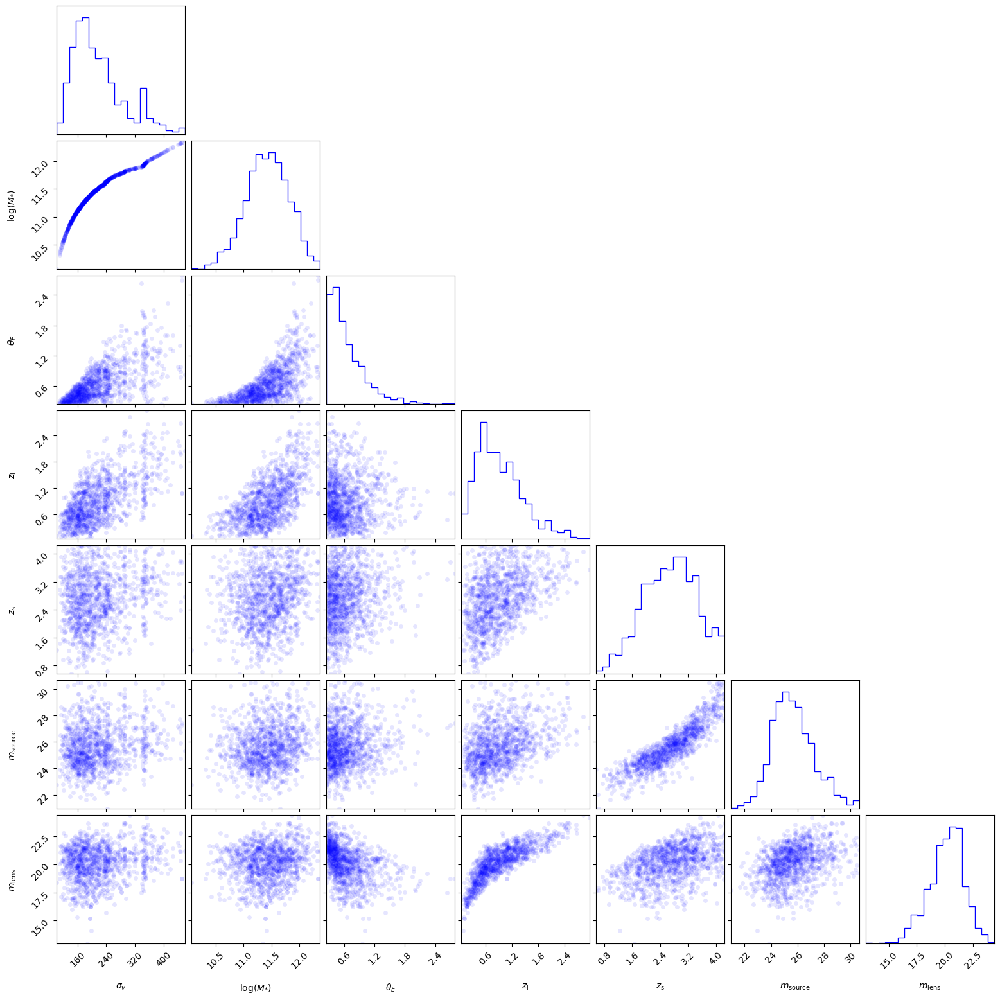

In [20]:
hist2dkwargs = {
    "plot_density": False,
    "plot_contours": False,
    "plot_datapoints": True,
    "color": "b",
    "data_kwargs": {"ms": 5},
}
corner.corner(np.array(cleaned_data), labels=labels, **hist2dkwargs) ##error clean_data is empty
plt.show()

## Choose a random lens

In [21]:
len(lens_population)

1125

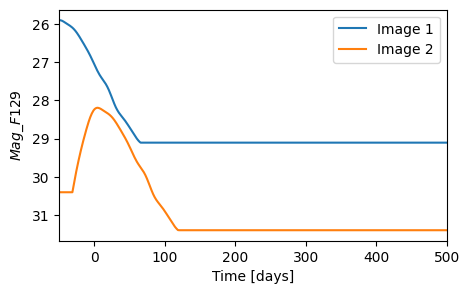

In [22]:
time = np.linspace(-50, 500, 500)
# light_curve = lens_class_test.source[0].variability_class.kwargs_model

#print("This is a type", lens_class.source[0].sn_type, "SN")
#for lensed_source in range(len(lens_population)):
lens_population_1= lens_population[178]
magnitude = lens_population_1.point_source_magnitude(band="F129", lensed=True, time=time)

plt.figure(figsize=(5, 3))
plt.plot(time, magnitude[0][0], label="Image 1")
plt.plot(time, magnitude[0][1], label="Image 2")
plt.gca().invert_yaxis()
plt.ylabel(r"$Mag\_{F129}$")
plt.xlabel("Time [days]")
plt.xlim(-50, 500)
plt.legend()

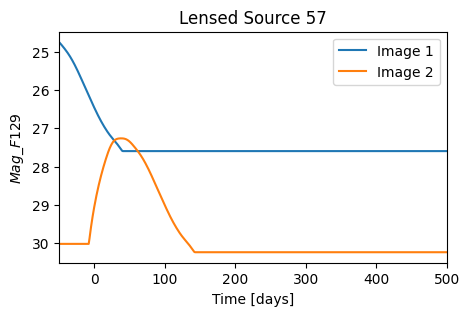

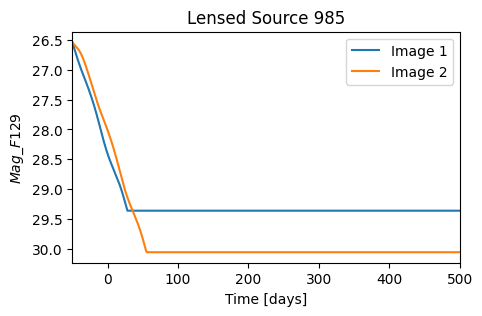

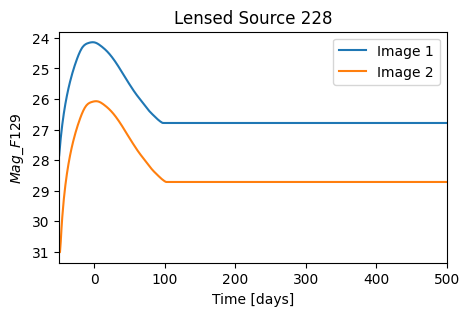

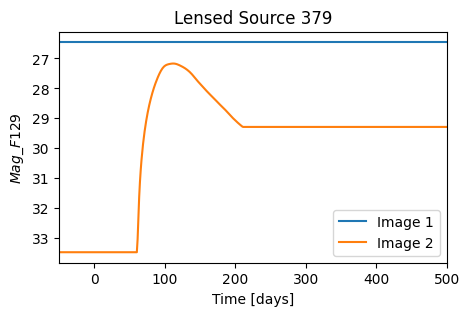

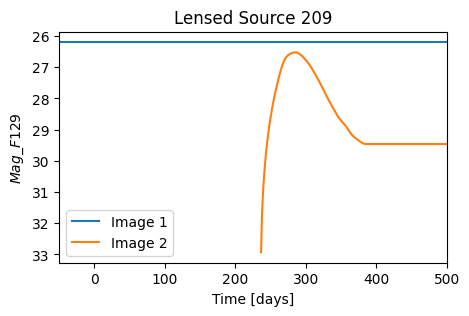

...

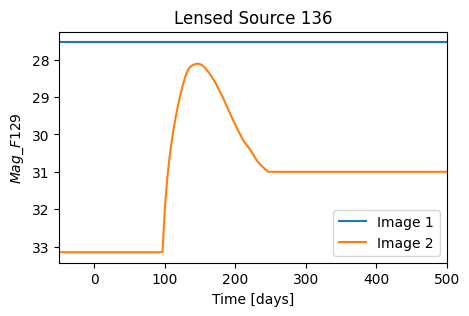

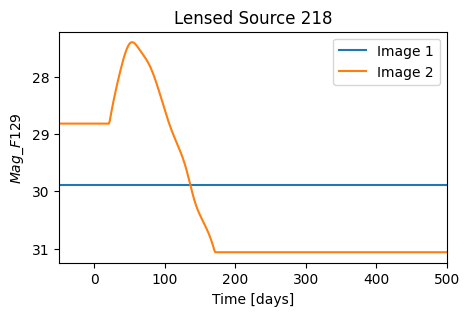

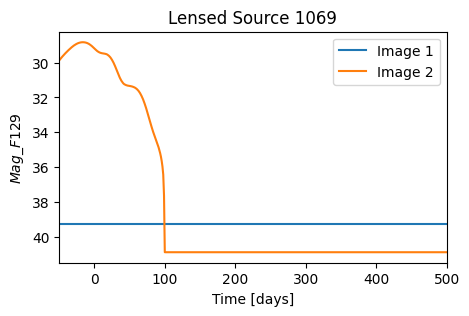

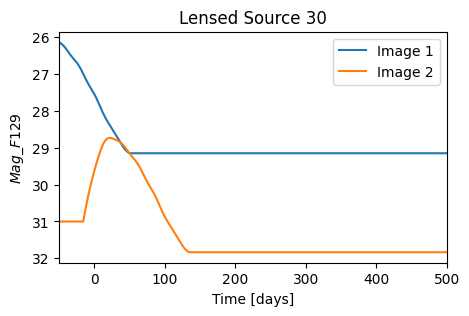

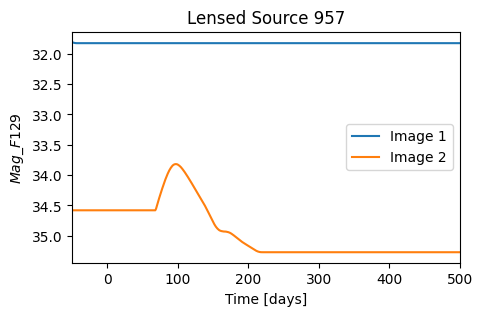

In [23]:
time = np.linspace(-50, 500, 500)
# light_curve = lens_class_test.source[0].variability_class.kwargs_model

#print("This is a type", lens_class.source[0].sn_type, "SN")
#choose 20 random lenses    
lens_population_20 = np.random.choice(lens_population, size=20, replace=False)
#get the original index of the lens
lens_population_20_idx = [lens_population.index(lens) for lens in lens_population_20]
for idx_lens in range(len(lens_population_20)):
    magnitude = lens_population_20[idx_lens].point_source_magnitude(band="F129", lensed=True, time=time)
    plt.figure(figsize=(5, 3))
    plt.plot(time, magnitude[0][0], label="Image 1")
    plt.plot(time, magnitude[0][1], label="Image 2")
    plt.title(f"Lensed Source {lens_population_20_idx[idx_lens]}")
    plt.gca().invert_yaxis()
    plt.ylabel(r"$Mag\_{F129}$")
    plt.xlabel("Time [days]")
    plt.xlim(-50, 500)
    plt.legend()

## Simulate images 

In [24]:
time = np.array([-25, 0, 50, 80, 90, 100, 125, 150, 200, 250])
time_series_images = []
for t in time:
    image_roman = simulate_roman_image(
        lens_population_1,
        band="F129",
        #mag_zero_point=27,
        num_pix=71,
        #transform_pix2angle=np.array([[0.11, 0], [0, 0.11]]),
        detector=1,
        detector_pos=(2000, 2000),
        oversample=5,
        #psf_directory="/Users/narayankhadka/Downloads/cached_webb_psf/",  # replace this path
        psf_directory = "/Users/epadilla/OneDrive/LSST-strong-lensing/data_public/webbpsf/cached_webb_psf",
        # with the path where you have downloaded webbpsf.
        t_obs=t,
        with_source=True,
        with_deflector=True,
        ra=30,
        dec=-30,
        add_noise=True,
        seed=None,
    )
    time_series_images.append(image_roman)

In [25]:
pix_coord = point_source_coordinate_properties(
    lens_class=lens_class,
    #band="F184",
    band="F129",
    mag_zero_point=27,
    delta_pix=0.11,
    num_pix=71,
    transform_pix2angle=np.array([[0.11, 0], [0, 0.11]]),
)["image_pix"]

NameError: name 'lens_class' is not defined

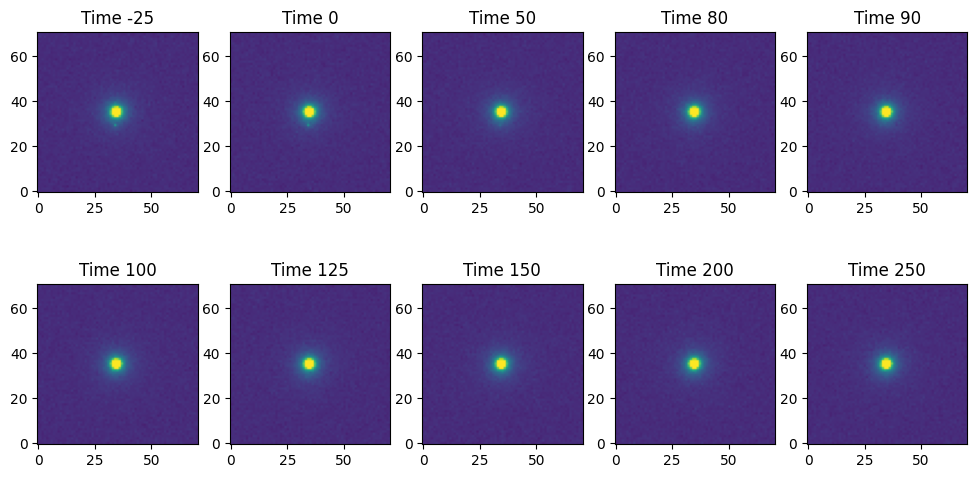

In [ ]:
#plot the time series images
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i, lens in enumerate(time_series_images):
    axes[i//5, i%5].imshow(lens, origin="lower", cmap="viridis", vmin=-0.5, vmax=3.5)
    axes[i//5, i%5].set_title(f"Time {time[i]}")
plt.show()

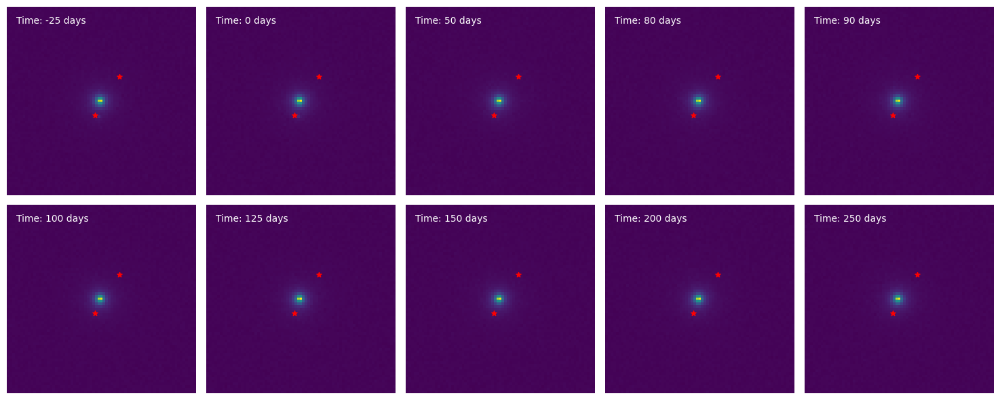

In [ ]:
image_montage = create_image_montage_from_image_list(
    num_rows=2,
    num_cols=5,
    images=time_series_images,
    time=time,
    image_center=pix_coord,
)

#should show a lensed arc?

/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/sncosmo/models.py:189: RuntimeWarning: invalid value encountered in log10
  result[i] = -2.5 * np.log10(f / zpf)
/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/sncosmo/models.py:189: RuntimeWarning: invalid value encountered in log10
  result[i] = -2.5 * np.log10(f / zpf)
/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/sncosmo/models.py:189: RuntimeWarning: divide by zero encountered in log10
  result[i] = -2.5 * np.log10(f / zpf)
/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/sncosmo/models.py:189: RuntimeWarning: invalid value encountered in log10
  result[i] = -2.5 * np.log10(f / zpf)
/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/sncosmo/models.py:189: RuntimeWarning: divide by zero encountered in log10
  result[i] = -2.5 * np.log10(f / zpf)
/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/sncosmo/models.py:189: RuntimeWarning: invalid value encountered in log10
  result[i] = -2.5 * np

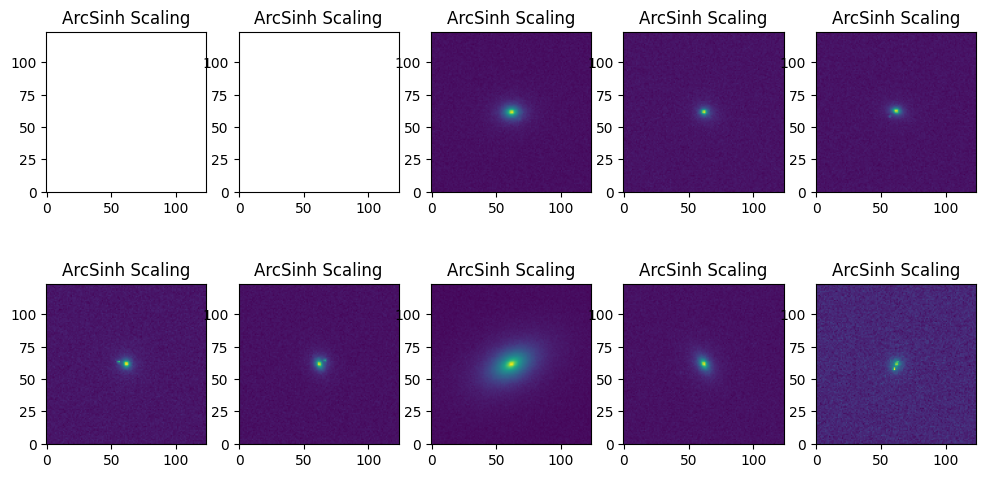

In [ ]:
from slsim.Plots.lens_plots import LensingPlots

test_lens_list = []
for _ in range(10):
    lens = lens_pop.select_lens_at_random(**kwargs_lens_cut_plot)
    test_lens_list.append(lens)


psf_directory = "/Users/epadilla/OneDrive/LSST-strong-lensing/data_public/webbpsf/cached_webb_psf"

#plot the simulation
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
#plot the 10 lenses
for i, lens in enumerate(test_lens_list):
    arcsinh_scaling_lens  =  simulate_roman_image(lens, band="F106", num_pix=124, oversample=5, add_noise=True, with_deflector=True)
    axes[i//5, i%5].imshow(np.arcsinh(arcsinh_scaling_lens), origin="lower", cmap="viridis")
    #axes[i//5, i%5].colorbar()
    axes[i//5, i%5].set_title("ArcSinh Scaling")
plt.show()

In [ ]:
def make_time_series(lens_class, with_source, with_deflector):
  """Generate list of images across time for given source/deflector flags."""
  time_series_images = []
  for t in sample_times:
      image_roman = simulate_roman_image(
          lens_class,
          band="F129",
          num_pix=124,
          oversample=5,
          add_noise=True,
          with_source=with_source,
          with_deflector=with_deflector,
          t_obs=t,
      )
      time_series_images.append(image_roman)
  return time_series_images

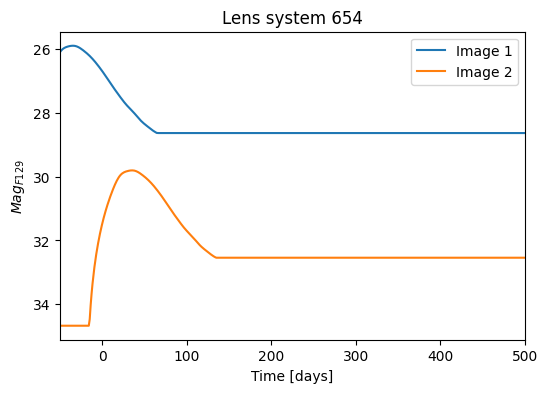

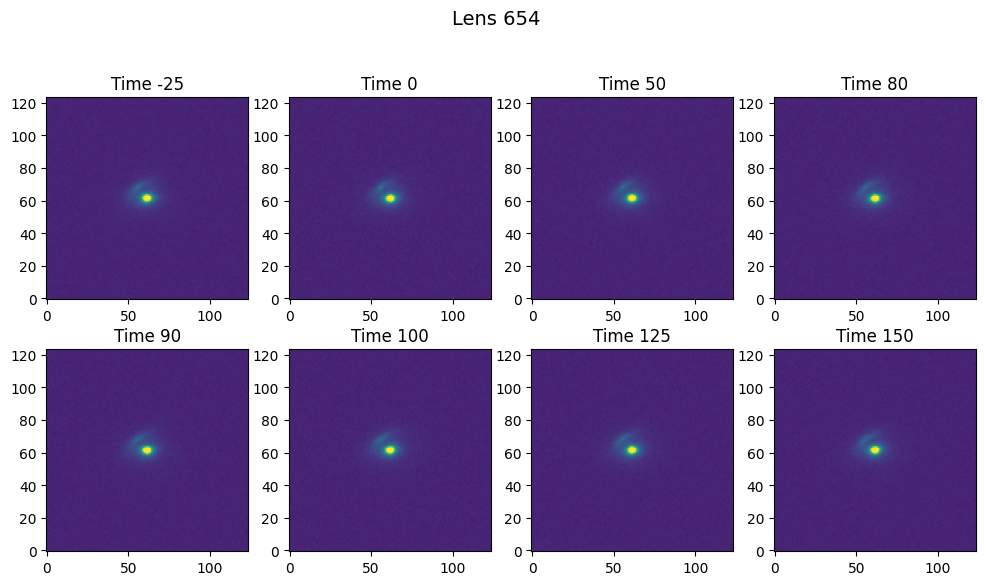

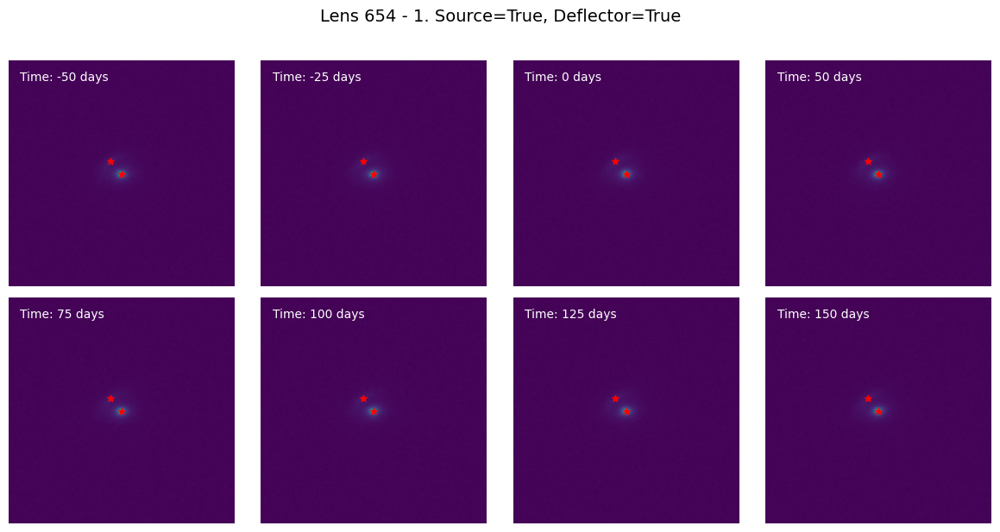

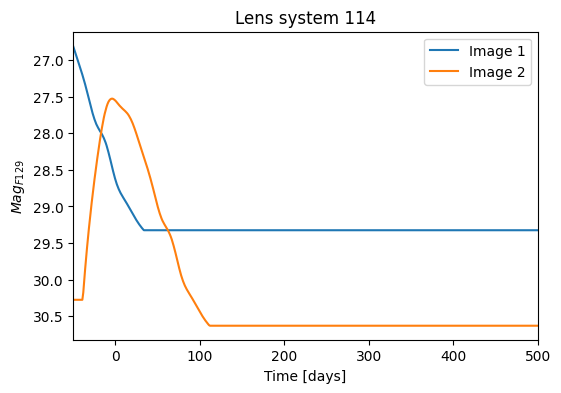

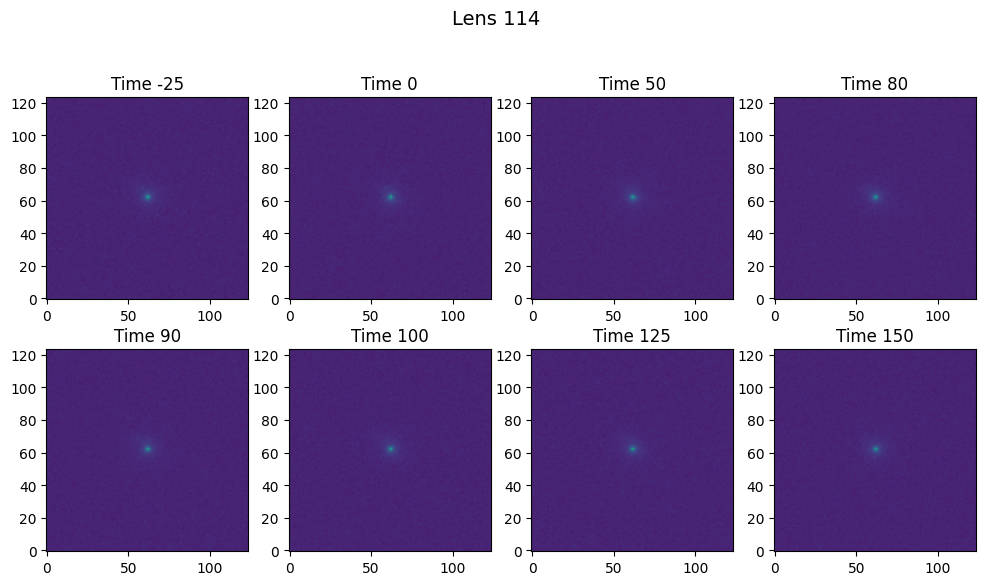

...

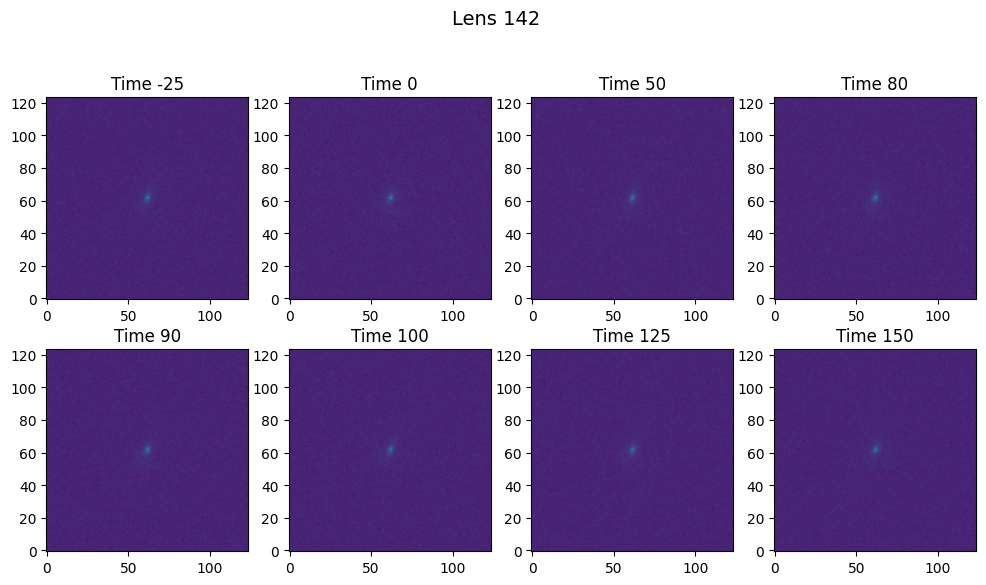

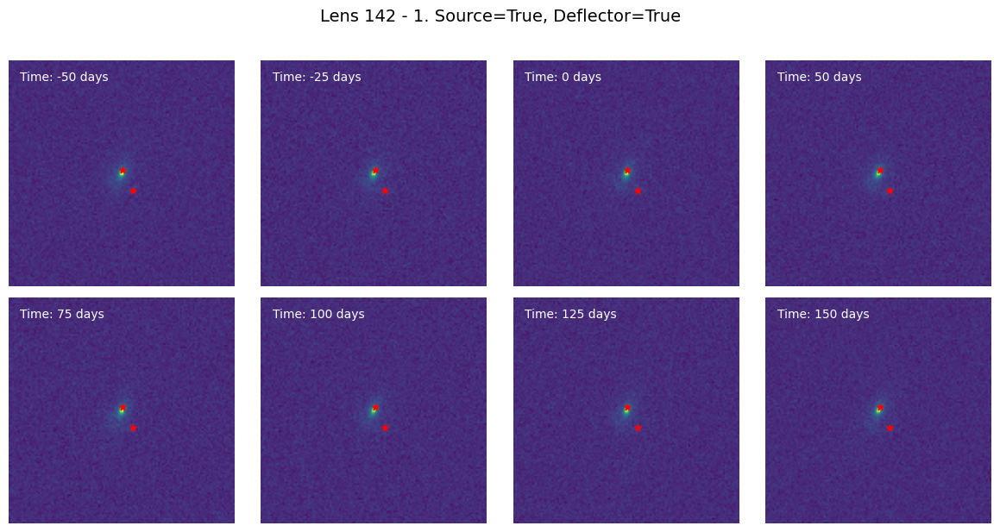

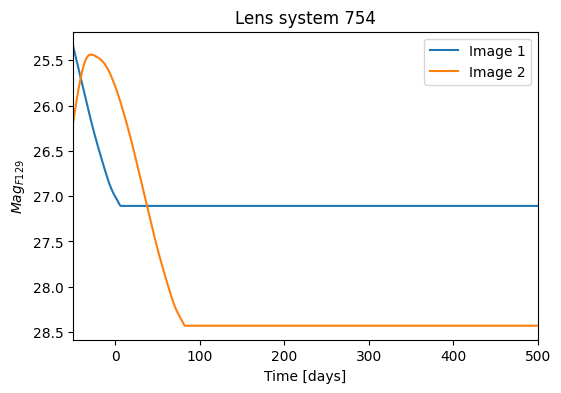

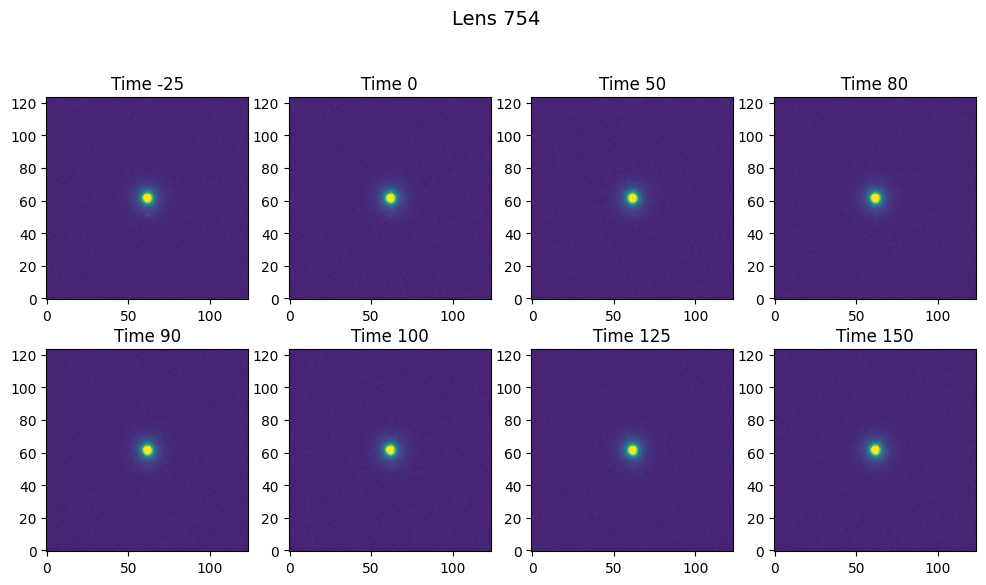

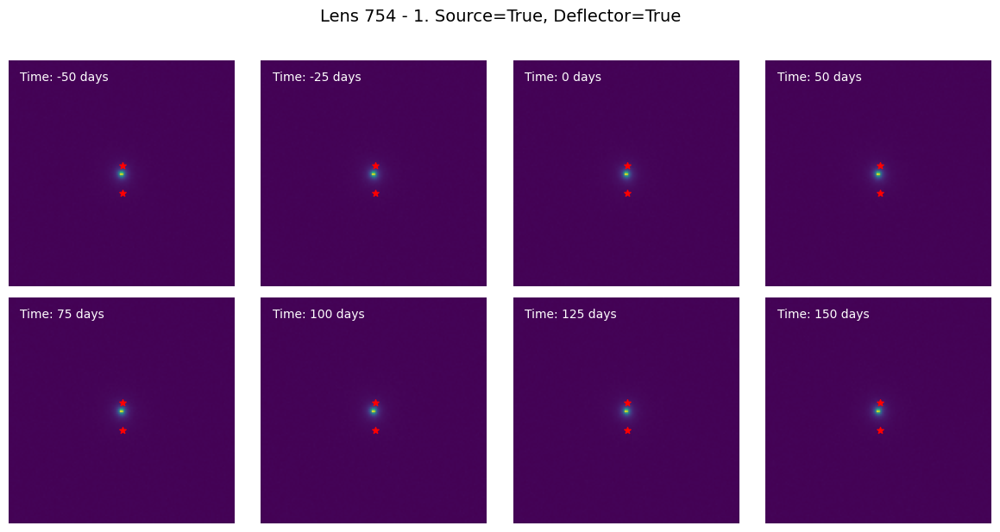

[local path removed]slsim/slsim/Sources/Supernovae/supernova.py:114: UserWarning: bandpass 'f106' [8900, .., 12400] outside spectral range [10019.6, .., 100196]
Ignoring bandpass for now. Use extended wavelength SN models found here: https://github.com/LSST-strong-lensing/data_public/tree/main/sncosmo_sn_models
  warn(


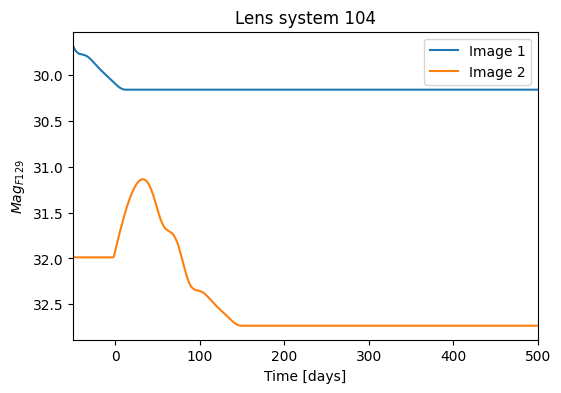

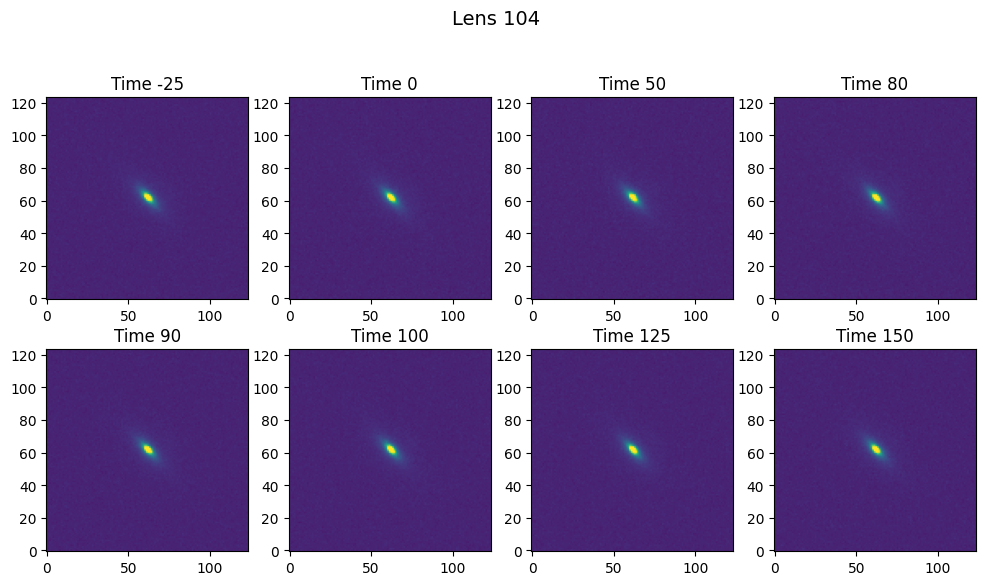

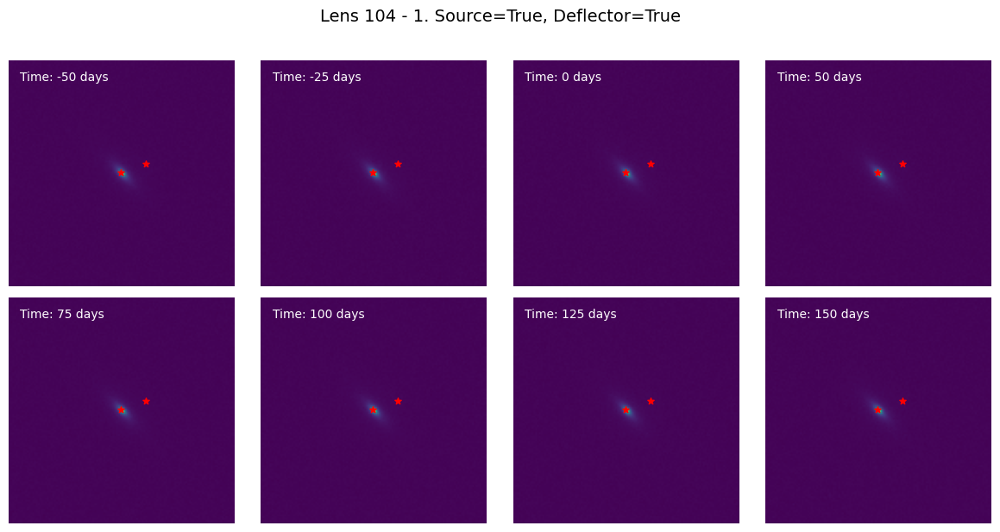

In [ ]:
import random
from slsim.ImageSimulation.roman_image_simulation import simulate_roman_image
# Pick 10 random systems from lens_population and display their lightcurves and image montages
random.seed(42)

random_indices = random.sample(range(len(lens_population)), 10)

# sample_times = np.array([-50, -25, 0, 50, 75, 
#                          100, 125, 150, 175, 200, 
#                          225, 250, 275, 300, 325])

sample_times = np.array([-50, -25, 0, 50, 75, 
                         100, 125, 150])


for idx in random_indices:
    lens_class = lens_population[idx]
    
    # Light Curve
    times = np.linspace(-50, 500, 500)

    magnitude = lens_class.point_source_magnitude(
        band="F129", lensed=True, time=times
    )

    plt.figure(figsize=(6, 4))
    for i in range(len(magnitude[0])):
        plt.plot(times, magnitude[0][i], label=f"Image {i+1}")
    plt.gca().invert_yaxis()
    plt.ylabel(r"$Mag_{F129}$")
    plt.xlabel("Time [days]")
    plt.xlim(-50, 500)
    plt.title(f"Lens system {idx}")
    plt.legend()
    plt.show()

    # Image Montages
    images_both      = make_time_series(lens_class, with_source=True,  with_deflector=True)
    images_deflector = make_time_series(lens_class, with_source=False, with_deflector=True)
    images_source    = make_time_series(lens_class, with_source=True,  with_deflector=False)
    images_sub       = [img_b - img_d for img_b, img_d in zip(images_both, images_deflector)]


    #plot the time series images
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for i, lens in enumerate(images_both):
        axes[i//4, i%4].imshow(lens, origin="lower", cmap="viridis", vmin=-0.5, vmax=4.5)
        axes[i//4, i%4].set_title(f"Time {time[i]}")
    fig.suptitle(f"Lens {idx}", fontsize=14, y=1.02)
    plt.show()

    pix_coord = point_source_coordinate_properties(
        lens_class=lens_class,
        band="F129",
        mag_zero_point=27,
        delta_pix=0.11,
        #num_pix=71,
        num_pix=124,
        transform_pix2angle=np.array([[0.11, 0], [0, 0.11]]),
    )["image_pix"]

    titles = [
        "1. Source=True, Deflector=True",
        "2. Source=False, Deflector=True",
        "3. Source=True, Deflector=False",
        "4. Source Only (Both - Deflector)"
    ]
    #images = [images_both, images_deflector, images_source]
    images = [images_both]


    for title, imgs in zip(titles, images):
        fig = create_image_montage_from_image_list(
            num_rows=2,
            num_cols=4,
            images=imgs,
            time=sample_times,
            image_center=pix_coord,
        )
        fig.suptitle(f"Lens {idx} - {title}", fontsize=14, y=1.02)
        fig.subplots_adjust(top=0.92)
        plt.show()